# 01 - Data exploration (NOAA AIS, NY Harbor, 9-15 Jan 2023)

Reads the cleaned observations and derived features produced by the pipeline (`python tasks.py pipeline`). Synthetic demo vessels are excluded.

> This is an educational maritime analytics portfolio project. Anomaly detections represent statistical or rule-based deviations, not evidence of illegal or hostile activity.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from maritime.database import read_sql
from maritime.config import get_settings
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE = '#2a78d6', '#eb6834'

## Ingestion and data quality

In [2]:
runs = read_sql("SELECT file_name, rows_raw, rows_in_bbox, rows_accepted, rows_rejected, rows_duplicate, "
                "rows_inserted FROM ingestion_runs ORDER BY file_name")
runs['pct_in_bbox'] = (100 * runs.rows_in_bbox / runs.rows_raw).round(2)
runs

,file_name,rows_raw,rows_in_bbox,rows_accepted,rows_rejected,rows_duplicate,rows_inserted,pct_in_bbox
0,AIS_2023_01_09.zip,8323136,246107,246103,0,6,246101,2.96
1,AIS_2023_01_10.zip,8135468,242472,242469,0,5,242467,2.98
2,AIS_2023_01_11.zip,7795074,251713,251708,0,5,251708,3.23
3,AIS_2023_01_12.zip,7648275,242561,242556,0,17,242544,3.17
4,AIS_2023_01_13.zip,7676204,244396,244394,0,4,244392,3.18
5,AIS_2023_01_14.zip,8084458,219129,219128,0,4,219125,2.71
6,AIS_2023_01_15.zip,8092890,211023,211000,0,30,210993,2.61


In [3]:
qr = read_sql("SELECT quality_report FROM ingestion_runs WHERE status='completed'").quality_report
miss = pd.DataFrame([q['missing_by_field'] for q in qr]).sum()
(100 * miss / runs.rows_in_bbox.sum()).sort_values(ascending=False).round(2).rename('% missing').to_frame()

,% missing
draft_m,48.05
imo,39.74
width_m,18.20
length_m,10.67
nav_status,4.80
cargo,4.66
call_sign,3.49
vessel_name,0.08
vessel_type,0.00
sog,0.00


## Reported speed by vessel-type group

In [4]:
steps = pd.read_parquet(get_settings().processed_dir / 'steps.parquet',
                        columns=['mmsi', 'base_datetime', 'sog', 'dt_s', 'implied_kn', 'vessel_type', 'is_synthetic'])
steps = steps[~steps.is_synthetic]
from maritime.processing.vessel_features import vessel_type_group
steps['group'] = steps.vessel_type.map(vessel_type_group)
moving = steps[steps.sog > 0.5]
moving.groupby('group').sog.describe(percentiles=[.5, .95]).round(1)

,count,mean,std,min,50%,95%,max
group,,,,,,,
cargo,31484.0,8.3,3.5,0.6,8.8,14.7,18.7
fishing,602.0,8.3,1.2,0.9,8.2,10.1,10.5
other,73991.0,9.7,8.1,0.6,7.9,27.7,50.7
passenger,141763.0,13.0,8.0,0.6,11.6,27.0,102.2
pleasure_sailing,1323.0,13.2,13.1,0.6,7.9,39.8,55.0
tanker,19323.0,6.9,3.7,0.6,7.5,12.3,17.2
tug_tow,225295.0,6.2,2.9,0.6,6.5,10.5,29.9


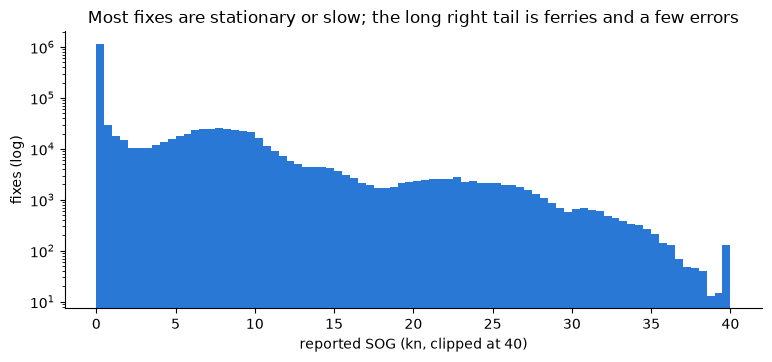

In [5]:
fig, ax = plt.subplots()
ax.hist(steps.sog.dropna().clip(0, 40), bins=80, color=BLUE)
ax.set_yscale('log'); ax.set_xlabel('reported SOG (kn, clipped at 40)'); ax.set_ylabel('fixes (log)')
ax.set_title('Most fixes are stationary or slow; the long right tail is ferries and a few errors');

## Reporting intervals and gaps

NOAA's files are downsampled to roughly one fix per minute, so the interval distribution peaks near 60 s.

count    1656734.0
mean         130.5
std         1967.4
min            1.0
5%            61.0
50%           70.0
95%          183.0
99%          362.0
max       494963.0
Name: dt_s, dtype: float64


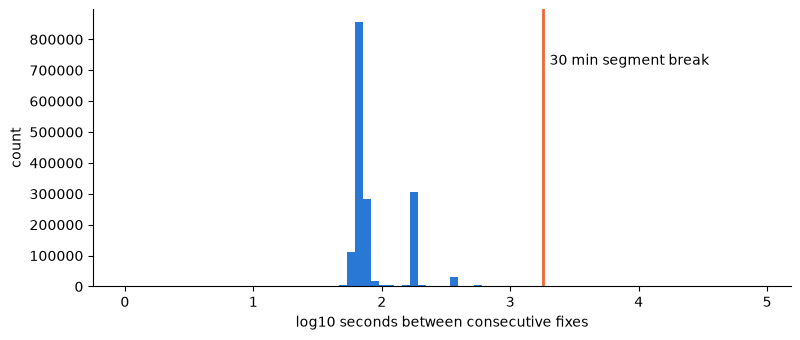

In [6]:
dt = steps.dt_s.dropna()
print(dt.describe(percentiles=[.05, .5, .95, .99]).round(1))
fig, ax = plt.subplots()
ax.hist(np.log10(dt.clip(1, 86400)), bins=80, color=BLUE)
ax.set_xlabel('log10 seconds between consecutive fixes'); ax.set_ylabel('count')
ax.axvline(np.log10(1800), color=ORANGE, lw=2); ax.text(np.log10(1800)+.05, ax.get_ylim()[1]*.8, '30 min segment break');

## Implied vs reported speed

Large disagreements at short intervals are mostly GNSS noise; the speed-discrepancy rule only looks at 30-600 s intervals and >200 m steps.

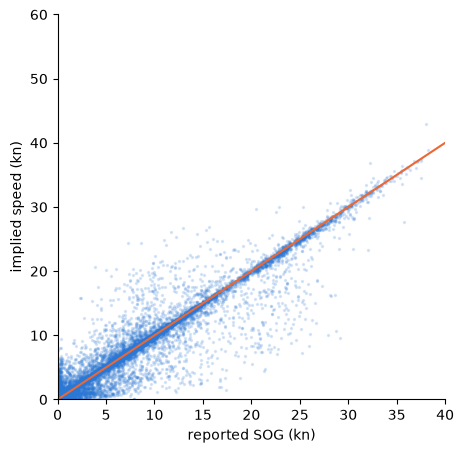

In [7]:
s = steps[(steps.dt_s.between(30, 600)) & steps.sog.notna()].sample(50000, random_state=0)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(s.sog, s.implied_kn.clip(0, 60), s=2, alpha=.15, color=BLUE)
ax.plot([0, 40], [0, 40], color=ORANGE, lw=1.5); ax.set_xlim(0, 40); ax.set_ylim(0, 60)
ax.set_xlabel('reported SOG (kn)'); ax.set_ylabel('implied speed (kn)');

## Track features and model scores (aggregate only)

2649 vessel-day tracks; {'train (in-sample)': 1937, 'evaluation (out-of-sample)': 655}


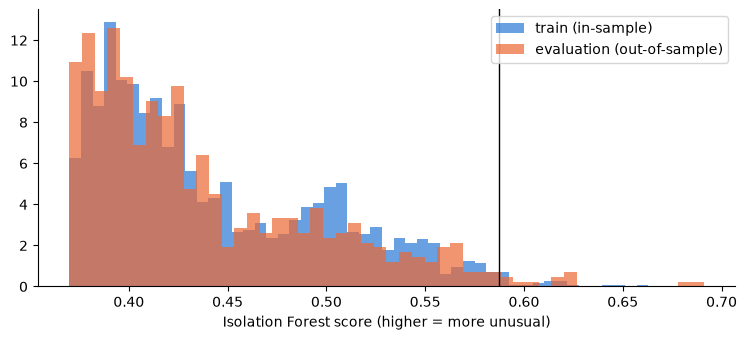

In [8]:
tf = pd.read_parquet(get_settings().processed_dir / 'track_features.parquet')
tf = tf[~tf.is_synthetic]
sc = pd.read_parquet(get_settings().processed_dir / 'track_scores.parquet')
print(len(tf), 'vessel-day tracks;', sc.split.value_counts().to_dict())
fig, ax = plt.subplots()
for split, c in [('train (in-sample)', BLUE), ('evaluation (out-of-sample)', ORANGE)]:
    ax.hist(sc[sc.split == split].score, bins=50, alpha=.7, color=c, label=split, density=True)
thr = json.load(open('../reports/model_cards/real_data_diagnostics.json'))['threshold']
ax.axvline(thr, color='k', lw=1); ax.legend(); ax.set_xlabel('Isolation Forest score (higher = more unusual)');

In [9]:
json.load(open('../reports/model_cards/real_data_diagnostics.json'))['seed_stability']

{'seeds': [0, 1, 2, 3, 4],
 'mean_spearman': 0.9916,
 'min_spearman': 0.9877,
 'mean_top20_jaccard': 0.7273}

## Takeaways

- ~3% of nationwide fixes fall in the NY Harbor box; hard rejects there are essentially zero because NOAA pre-cleans, so the soft flags (heading 511, COG 360) carry most quality information.
- Tugs and ferries dominate the harbour; vessel-type grouping matters for any speed rule.
- Isolation Forest scores are stable across seeds and similar between training and later days, which supports using them as a ranking for review, not as a classifier.